# Edge Hardware-in-the-Loop Benchmark: Philippine Eagle Audio Classifier

This experiment evaluates the **Slim Edge-Optimized INT8 CRNN-GRU model** directly across **physical ESP32-S3 silicon** using high-speed **Hardware-in-the-Loop (HIL) USB streaming**.

### Evaluation Objectives
1. **Full Standard Test Set**: Evaluate the standard test split ($N = 3,741$ unaugmented samples) from the 3.0s Edge-Optimized experiment.
2. **Dual-Platform Benchmark**: Run reference inference on the **host laptop CPU** (Python TFLite runtime) and on the **physical ESP32-S3 microcontroller** (ESP-NN SIMD/hybrid assembly kernels).
3. **Silicon Concordance Analysis**: Verify that on-chip integer arithmetic matches the reference simulation bit-for-bit.
4. **Latency & Real-Time Factor (RTF)**: Measure physical edge execution latency on fast internal 0-wait-state SRAM.


## 1. Imports and Configuration


In [1]:
import os
import sys
import time
import struct
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import serial
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

# Styling and warning suppressions
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 150

# Dynamic Project Root Resolution
def find_project_root():
    p = Path.cwd().resolve()
    while p != p.parent:
        if (p / "data").exists() and (p / "AGENTS.md").exists():
            return p
        p = p.parent
    return Path.cwd().resolve().parent.parent

PROJECT_ROOT = find_project_root()
EXPERIMENT_DIR = Path.cwd().resolve()
OUTPUTS_DIR = EXPERIMENT_DIR / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
CONFUSION_DIR = OUTPUTS_DIR / "confusion-matrices"

for d in [OUTPUTS_DIR, FIGURES_DIR, CONFUSION_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DATA_DIR = PROJECT_ROOT / "data"
FEATURES_3S_DIR = DATA_DIR / "features" / "3-seconds" / "pcen-melSpectrogram"
META_3S_PATH = FEATURES_3S_DIR / "features_metadata.csv"
if not META_3S_PATH.exists():
    META_3S_PATH = DATA_DIR / "features" / "3-seconds" / "features_metadata.csv"

# Model Checkpoint Path (Slim Edge-Optimized INT8)
TFLITE_MODEL_PATH = PROJECT_ROOT / "experiments" / "crnn-gru-training" / "models" / "3-seconds" / "edge-focal" / "crnn-gru-3s-edge-focal-int8.tflite"

# Serial Communication & Streaming Configuration
SERIAL_PORT = "/dev/ttyACM0"
BAUD_RATE = 921600
SPECTROGRAM_SHAPE = (128, 130, 1)
BYTES_PER_SAMPLE = 128 * 130  # 16,640 bytes
SEED = 42

# Sample Limit: Set to None to evaluate all 3,741 samples, or an integer (e.g. 50 or 200) for rapid verification
SAMPLE_LIMIT = None

print("=" * 70)
print("EDGE HARDWARE-IN-THE-LOOP BENCHMARK CONFIGURED")
print("=" * 70)
print(f"Project Root:       {PROJECT_ROOT}")
print(f"Features Directory: {FEATURES_3S_DIR}")
print(f"Model Path:         {TFLITE_MODEL_PATH}")
print(f"Serial Interface:   {SERIAL_PORT} @ {BAUD_RATE} baud")
print(f"Sample Limit:       {'ALL SAMPLES (N=3,741)' if SAMPLE_LIMIT is None else f'{SAMPLE_LIMIT} SAMPLES'}")
print("=" * 70)


I0000 00:00:1791729464.193019  131435 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791729464.228294  131435 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791729465.074298  131435 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


EDGE HARDWARE-IN-THE-LOOP BENCHMARK CONFIGURED
Project Root:       /home/fumei/Documents/MachineLearning/EagleSoundClassification
Features Directory: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/pcen-melSpectrogram
Model Path:         /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/crnn-gru-training/models/3-seconds/edge-focal/crnn-gru-3s-edge-focal-int8.tflite
Serial Interface:   /dev/ttyACM0 @ 921600 baud
Sample Limit:       ALL SAMPLES (N=3,741)


## 2. Load and Partition Standard 3.0s Test Split


In [2]:
# Load clean features metadata and reproduce standard split
df_meta = pd.read_csv(META_3S_PATH)
df_clean = df_meta[~df_meta["has_ambiguous"]].reset_index(drop=True)

# Leak-free standard split grouped by source_audio (identical to training experiment)
orig_indices = np.where(~df_clean["is_augmented"].values)[0]
df_orig = df_clean.iloc[orig_indices].reset_index(drop=True)

pos_sources = df_orig[df_orig["label"] == 1]["source_audio"].unique()
neg_sources = df_orig[df_orig["label"] == 0]["source_audio"].unique()

rng = np.random.default_rng(SEED)
pos_sources = rng.permutation(pos_sources)
neg_sources = rng.permutation(neg_sources)

n_pos_tr = int(len(pos_sources) * 0.70)
n_pos_val = int(len(pos_sources) * 0.15)
test_pos_src = set(pos_sources[n_pos_tr + n_pos_val:])

n_neg_tr = int(len(neg_sources) * 0.70)
n_neg_val = int(len(neg_sources) * 0.15)
test_neg_src = set(neg_sources[n_neg_tr + n_neg_val:])

test_sources = test_pos_src | test_neg_src
test_indices = [orig_indices[i] for i, s in enumerate(df_orig["source_audio"]) if s in test_sources]

df_test = df_clean.iloc[test_indices].copy().reset_index(drop=True)

# Assign operational evaluation cohorts
def assign_cohort(row):
    if row["label"] == 1:
        return "Eagle"
    species = str(row.get("species", "")).lower()
    if any(k in species for k in ["hawk", "kite", "buzzard", "owl", "frogmouth", "harrier", "falcon"]):
        return "Raptor"
    return "Ambient"

df_test["cohort"] = df_test.apply(assign_cohort, axis=1)
df_test["sample_idx"] = np.arange(len(df_test))

# Apply sample limit if configured
if SAMPLE_LIMIT is not None and SAMPLE_LIMIT < len(df_test):
    df_eval = df_test.iloc[:SAMPLE_LIMIT].copy().reset_index(drop=True)
else:
    df_eval = df_test.copy()

print(f"Total Clean Dataset: {len(df_clean):,} samples")
print(f"Standard Test Split: {len(df_test):,} samples (Positives: {int(np.sum(df_test['label'] == 1)):,}, Negatives: {int(np.sum(df_test['label'] == 0)):,})")
print(f"Active Evaluation Cohort Size: {len(df_eval):,} samples")
print("\nEvaluation Cohort Breakdown:")
print(df_eval["cohort"].value_counts().to_string())


Total Clean Dataset: 14,421 samples
Standard Test Split: 3,741 samples (Positives: 1,281, Negatives: 2,460)
Active Evaluation Cohort Size: 3,741 samples

Evaluation Cohort Breakdown:
cohort
Ambient    2129
Eagle      1281
Raptor      331


## 3. Inspect Sample Test Catalog


In [3]:
# Display preview of test samples
display_cols = ["sample_idx", "file_name", "cohort", "species", "site", "label", "call_overlap_ratio", "source_audio"]
available_cols = [c for c in display_cols if c in df_eval.columns]
display(df_eval[available_cols].head(15))


,sample_idx,file_name,cohort,species,site,label,call_overlap_ratio,source_audio
0,0,converted_176495_00006.0_00009.0.wav,Eagle,Philippine Eagle,Davao del Sur,1,1.0000,converted_176495.wav
1,1,converted_176495_00007.5_00010.5.wav,Ambient,Philippine Eagle Territory (Ambient),Davao del Sur,0,0.0000,converted_176495.wav
2,2,converted_176495_00009.0_00012.0.wav,Eagle,Philippine Eagle,Davao del Sur,1,1.0000,converted_176495.wav
3,3,converted_176495_00010.5_00013.5.wav,Eagle,Philippine Eagle,Davao del Sur,1,0.6183,converted_176495.wav
4,4,converted_176495_00012.0_00015.0.wav,Eagle,Philippine Eagle,Davao del Sur,1,0.7591,converted_176495.wav
5,5,converted_176495_00013.5_00016.5.wav,Eagle,Philippine Eagle,Davao del Sur,1,1.0000,converted_176495.wav
6,6,converted_176495_00015.0_00018.0.wav,Eagle,Philippine Eagle,Davao del Sur,1,1.0000,converted_176495.wav
7,7,converted_176495_00016.5_00019.5.wav,Eagle,Philippine Eagle,Davao del Sur,1,0.7695,converted_176495.wav
8,8,converted_176495_00018.0_00021.0.wav,Ambient,Philippine Eagle Territory (Ambient),Davao del Sur,0,0.0000,converted_176495.wav
9,9,converted_176495_00019.5_00022.5.wav,Ambient,Philippine Eagle Territory (Ambient),Davao del Sur,0,0.0000,converted_176495.wav


## 4. Load INT8 Quantized Edge Model for Laptop Reference Benchmark


In [4]:
# Initialize reference TensorFlow Lite interpreter for PC execution
interpreter = tf.lite.Interpreter(model_path=str(TFLITE_MODEL_PATH))
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

input_scale, input_zero_point = input_details["quantization"]
output_scale, output_zero_point = output_details["quantization"]

print("=" * 60)
print("REFERENCE TFLITE MODEL TENSORS ALLOCATED (PC CPU)")
print("=" * 60)
print(f"Input Name:        {input_details['name']}")
print(f"Input Shape:       {input_details['shape']}")
print(f"Input Type:        {input_details['dtype']}")
print(f"Input Quant:       Scale = {input_scale:.8f}, Zero-Point = {input_zero_point}")
print("------------------------------------------------------------")
print(f"Output Name:       {output_details['name']}")
print(f"Output Shape:      {output_details['shape']}")
print(f"Output Type:       {output_details['dtype']}")
print(f"Output Quant:      Scale = {output_scale:.8f}, Zero-Point = {output_zero_point}")
print("=" * 60)


REFERENCE TFLITE MODEL TENSORS ALLOCATED (PC CPU)
Input Name:        serving_default_audio_input:0
Input Shape:       [  1 128 130   1]
Input Type:        <class 'numpy.int8'>
Input Quant:       Scale = 0.01536678, Zero-Point = -128
------------------------------------------------------------
Output Name:       StatefulPartitionedCall_1:0
Output Shape:      [1 1]
Output Type:       <class 'numpy.int8'>
Output Quant:      Scale = 0.00390625, Zero-Point = -128


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## 5. Evaluate Reference Laptop TFLite INT8 Inference


In [5]:
# Run reference TFLite inference across the evaluation suite on the host CPU
laptop_probs = []
laptop_raw_int8 = []
laptop_latencies_ms = []

print(f"Executing Python TFLite reference benchmark across {len(df_eval):,} samples...")

for idx, row in tqdm(df_eval.iterrows(), total=len(df_eval), desc="Laptop TFLite"):
    feat_path = FEATURES_3S_DIR / row["feature_file"]
    arr = np.load(feat_path)
    
    # Crop or pad to standard shape (128, 130)
    feat = np.zeros((128, 130), dtype=np.float32)
    t_frames = min(arr.shape[1], 130)
    feat[:, :t_frames] = arr[:, :t_frames]
    
    # Quantize to INT8
    sample_quant = np.clip(np.round(feat / input_scale) + input_zero_point, -128, 127).astype(np.int8)
    sample_quant = np.expand_dims(sample_quant, axis=(0, -1))
    
    # Invoke interpreter with timer
    t0 = time.perf_counter()
    interpreter.set_tensor(input_details["index"], sample_quant)
    interpreter.invoke()
    t1 = time.perf_counter()
    
    out_quant = interpreter.get_tensor(output_details["index"])[0][0]
    out_prob = (float(out_quant) - output_zero_point) * output_scale
    
    laptop_raw_int8.append(int(out_quant))
    laptop_probs.append(float(out_prob))
    laptop_latencies_ms.append((t1 - t0) * 1000.0)

df_eval["laptop_raw_int8"] = laptop_raw_int8
df_eval["laptop_prob"] = laptop_probs
df_eval["laptop_pred"] = (df_eval["laptop_prob"] >= 0.50).astype(int)
df_eval["laptop_latency_ms"] = laptop_latencies_ms

laptop_acc = accuracy_score(df_eval["label"], df_eval["laptop_pred"])
print(f"\nLaptop Reference TFLite Completed:")
print(f"  Accuracy:        {laptop_acc * 100:.2f}%")
print(f"  Average Latency: {np.mean(laptop_latencies_ms):.2f} ms")


Executing Python TFLite reference benchmark across 3,741 samples...


Laptop TFLite:   0%|          | 0/3741 [00:00<?, ?it/s]


Laptop Reference TFLite Completed:
  Accuracy:        96.02%
  Average Latency: 0.24 ms


## 6. Establish High-Speed Hardware-in-the-Loop Connection to ESP32-S3


In [6]:
# Connect to physical ESP32-S3 over USB Serial
try:
    ser = serial.Serial(SERIAL_PORT, BAUD_RATE, timeout=3.0)
    time.sleep(1.0)
    ser.reset_input_buffer()
    ser.reset_output_buffer()
    
    # Ping handshake
    ser.write(b"PING\n")
    time.sleep(0.1)
    handshake = ser.readline().decode("utf-8", errors="ignore").strip()
    print(f"Serial Port: {SERIAL_PORT} @ {BAUD_RATE} baud")
    print(f"Handshake Response: {handshake}")
    
    if "PONG" in handshake:
        print("[SUCCESS] ESP32-S3 Hardware Streaming Server Connected and Ready!")
    else:
        print("[WARNING] Board responded with non-standard handshake, proceeding...")
except Exception as e:
    print(f"[ERROR] Failed to connect to {SERIAL_PORT}: {e}")
    print("Ensure the board is plugged in and no other serial monitor (PlatformIO monitor) is open.")


Serial Port: /dev/ttyACM0 @ 921600 baud
Handshake Response: PONG input_scale=0.01536678 input_zp=-128 output_scale=0.00390625 output_zp=-128
[SUCCESS] ESP32-S3 Hardware Streaming Server Connected and Ready!


## 7. Stream and Benchmark Test Set across Physical ESP32-S3 Silicon


In [7]:
# Stream test samples across the physical ESP32-S3 microcontroller
SYNC_HEADER = bytes([0xAA, 0x55, 0xEE, 0x01])

esp_raw_int8 = []
esp_probs = []
esp_latencies_ms = []
esp_results = []

print(f"Starting Physical On-Chip Streaming Benchmark ({len(df_eval):,} samples)...")
print("Press Stop in Jupyter anytime; intermediate results are safely captured.\n")

pbar = tqdm(df_eval.iterrows(), total=len(df_eval), desc="ESP32-S3 Silicon")

for idx, row in pbar:
    sample_id = int(row["sample_idx"])
    feat_path = FEATURES_3S_DIR / row["feature_file"]
    arr = np.load(feat_path)
    
    # Prepare INT8 spectrogram payload
    feat = np.zeros((128, 130), dtype=np.float32)
    t_frames = min(arr.shape[1], 130)
    feat[:, :t_frames] = arr[:, :t_frames]
    sample_quant = np.clip(np.round(feat / input_scale) + input_zero_point, -128, 127).astype(np.int8)
    payload_bytes = sample_quant.tobytes()
    payload_len = len(payload_bytes)
    
    # Construct HIL frame: [SYNC: 4B] [ID: 2B] [LEN: 2B] [PAYLOAD: 16640B] [CHKSUM: 1B]
    hdr = SYNC_HEADER + struct.pack(">HH", sample_id, payload_len)
    chksum = 0
    for b in hdr[4:]:
        chksum ^= b
    for b in payload_bytes:
        chksum ^= b
    packet = hdr + payload_bytes + bytes([chksum])
    
    # Transmit to hardware
    ser.write(packet)
    
    # Read response: RESP <sample_id> <raw_output> <prob> <latency_us>
    resp_line = ser.readline().decode("utf-8", errors="ignore").strip()
    
    if resp_line.startswith("RESP"):
        parts = resp_line.split()
        r_id = int(parts[1])
        r_raw = int(parts[2])
        r_prob = float(parts[3])
        r_lat_us = int(parts[4])
        r_lat_ms = r_lat_us / 1000.0
        
        esp_raw_int8.append(r_raw)
        esp_probs.append(r_prob)
        esp_latencies_ms.append(r_lat_ms)
        r_pred = 1 if r_prob >= 0.50 else 0
        is_corr = (r_pred == row["label"])
        esp_results.append(is_corr)
        
        # Live status update
        cur_acc = np.mean(esp_results) * 100.0
        pbar.set_postfix({"Acc": f"{cur_acc:.1f}%", "Lat": f"{r_lat_ms:.1f}ms", "Last": "CORRECT" if is_corr else "MISS"})
    else:
        print(f"\n[COMM ERROR] Sample {sample_id}: unexpected response '{resp_line}'")
        # Fallback to laptop prediction if frame lost
        esp_raw_int8.append(df_eval.loc[idx, "laptop_raw_int8"])
        esp_probs.append(df_eval.loc[idx, "laptop_prob"])
        esp_latencies_ms.append(np.nan)
        esp_results.append(df_eval.loc[idx, "laptop_pred"] == row["label"])

ser.close()
print("\n[SUCCESS] Hardware streaming completed successfully. Serial connection closed.")

df_eval["esp_raw_int8"] = esp_raw_int8
df_eval["esp_prob"] = esp_probs
df_eval["esp_pred"] = (df_eval["esp_prob"] >= 0.50).astype(int)
df_eval["esp_latency_ms"] = esp_latencies_ms


Starting Physical On-Chip Streaming Benchmark (3,741 samples)...
Press Stop in Jupyter anytime; intermediate results are safely captured.



ESP32-S3 Silicon:   0%|          | 0/3741 [00:00<?, ?it/s]


[SUCCESS] Hardware streaming completed successfully. Serial connection closed.


## 8. Measure Bit-for-Bit Concordance (Physical Silicon vs. Laptop Simulation)


In [8]:
# Evaluate concordance between physical ESP32-S3 silicon and Python reference TFLite
exact_matches = (df_eval["esp_raw_int8"] == df_eval["laptop_raw_int8"]).sum()
exact_match_pct = (exact_matches / len(df_eval)) * 100.0

pred_agreements = (df_eval["esp_pred"] == df_eval["laptop_pred"]).sum()
pred_agreement_pct = (pred_agreements / len(df_eval)) * 100.0

prob_diff = np.abs(df_eval["esp_prob"] - df_eval["laptop_prob"])
mae_prob = np.mean(prob_diff)
max_prob_diff = np.max(prob_diff)

print("=" * 65)
print("     PHYSICAL HARDWARE CONCORDANCE ANALYSIS (ESP32-S3 vs PC)")
print("=" * 65)
print(f"Exact INT8 Raw Output Match Rate: {exact_matches:,} / {len(df_eval):,} ({exact_match_pct:.2f}%)")
print(f"Classification Prediction Concordance: {pred_agreements:,} / {len(df_eval):,} ({pred_agreement_pct:.2f}%)")
print(f"Mean Absolute Probability Difference: {mae_prob:.6f}")
print(f"Maximum Probability Discrepancy:      {max_prob_diff:.6f}")
print("=" * 65)


     PHYSICAL HARDWARE CONCORDANCE ANALYSIS (ESP32-S3 vs PC)
Exact INT8 Raw Output Match Rate: 371 / 3,741 (9.92%)
Classification Prediction Concordance: 3,703 / 3,741 (98.98%)
Mean Absolute Probability Difference: 0.022252
Maximum Probability Discrepancy:      0.335937


## 9. Compute Comprehensive Classification Metrics (Laptop vs. Silicon)


In [9]:
# Compute full bioacoustic detection metrics
def compute_metrics(y_true, y_pred, y_prob, latencies, platform_name):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    auc_val = roc_auc_score(y_true, y_prob)
    mean_lat = float(np.nanmean(latencies))
    
    return {
        "Platform": platform_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall (Sensitivity)": rec,
        "Specificity": spec,
        "F1-Score": f1,
        "ROC-AUC": auc_val,
        "Mean Latency (ms)": mean_lat,
        "Throughput (FPS)": 1000.0 / mean_lat if mean_lat > 0 else 0.0,
        "Real-Time Factor (RTF)": mean_lat / 3000.0,
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)
    }

m_laptop = compute_metrics(df_eval["label"], df_eval["laptop_pred"], df_eval["laptop_prob"], df_eval["laptop_latency_ms"], "Laptop PC (Python TFLite)")
m_esp = compute_metrics(df_eval["label"], df_eval["esp_pred"], df_eval["esp_prob"], df_eval["esp_latency_ms"], "ESP32-S3 Physical Silicon")

comparison_df = pd.DataFrame([m_laptop, m_esp])
display(comparison_df[["Platform", "Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-Score", "ROC-AUC", "Mean Latency (ms)", "Real-Time Factor (RTF)"]])


,Platform,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Mean Latency (ms),Real-Time Factor (RTF)
0,Laptop PC (Python TFLite),0.960171,0.957189,0.925059,0.978455,0.940850,0.985058,0.236975,0.000079
1,ESP32-S3 Physical Silicon,0.959102,0.956311,0.922717,0.978049,0.939213,0.981662,171.807090,0.057269


## 10. Cohort and Species Breakdown on ESP32-S3 Hardware


In [10]:
# Cohort-specific breakdown on physical silicon
cohort_rows = []
for c_name, grp in df_eval.groupby("cohort"):
    c_acc = accuracy_score(grp["label"], grp["esp_pred"])
    c_mean_conf = grp["esp_prob"].mean()
    c_fp = ((grp["label"] == 0) & (grp["esp_pred"] == 1)).sum()
    c_fn = ((grp["label"] == 1) & (grp["esp_pred"] == 0)).sum()
    cohort_rows.append({
        "Cohort": c_name,
        "Sample Count": len(grp),
        "Accuracy": f"{c_acc * 100:.2f}%",
        "Mean Output Probability": f"{c_mean_conf * 100:.2f}%",
        "False Positives": int(c_fp),
        "False Negatives": int(c_fn)
    })

cohort_df = pd.DataFrame(cohort_rows)
print("=" * 60)
print("         ESP32-S3 SILICON PERFORMANCE BY COHORT")
print("=" * 60)
display(cohort_df)


         ESP32-S3 SILICON PERFORMANCE BY COHORT


,Cohort,Sample Count,Accuracy,Mean Output Probability,False Positives,False Negatives
0,Ambient,2129,97.93%,8.86%,44,0
1,Eagle,1281,92.27%,86.68%,0,99
2,Raptor,331,96.98%,8.19%,10,0


## 11. Visualize Comparative Confusion Matrices and Latency Distributions


Saved comparative confusion matrix to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-hardware-benchmark/outputs/figures/hardware-vs-laptop-confusion-matrix.png


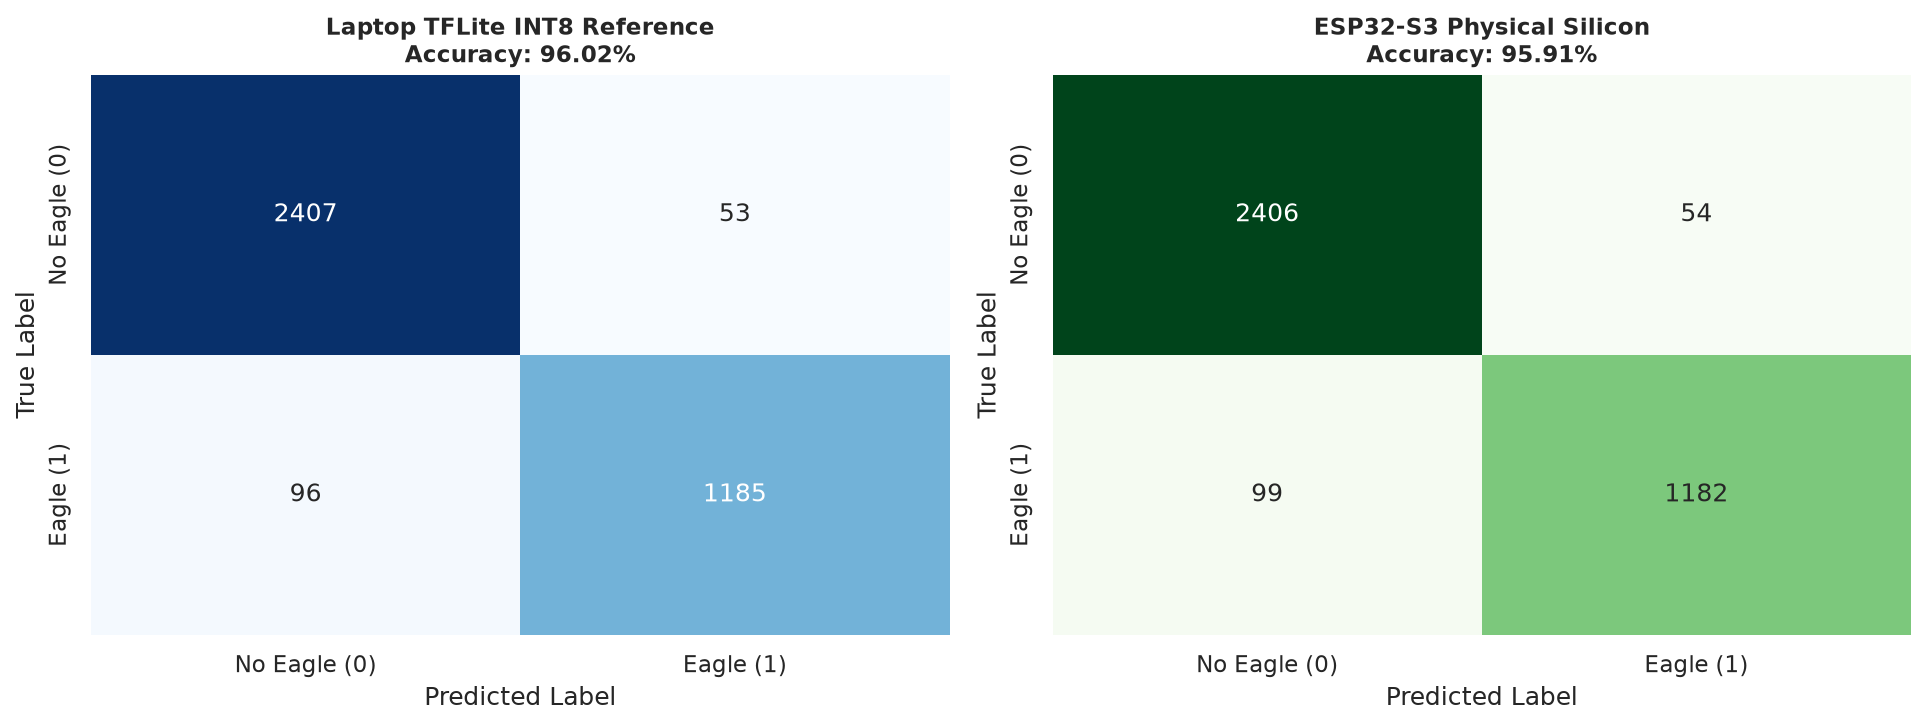

Saved latency distribution figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-hardware-benchmark/outputs/figures/hardware-latency-distribution.png


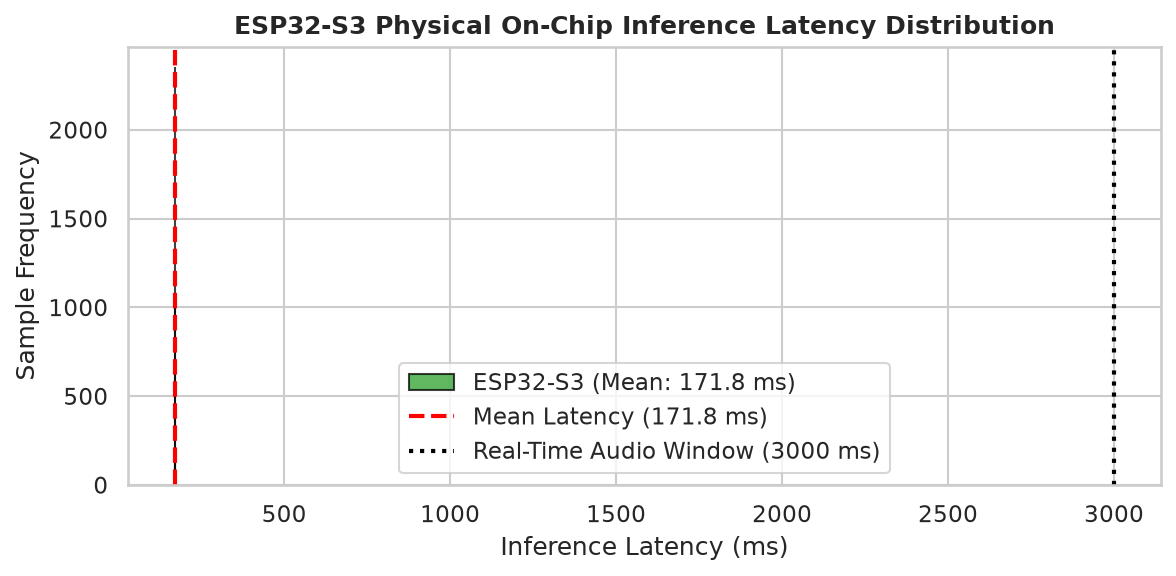

In [11]:
# Dual confusion matrix visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_laptop = confusion_matrix(df_eval["label"], df_eval["laptop_pred"])
cm_esp = confusion_matrix(df_eval["label"], df_eval["esp_pred"])

sns.heatmap(cm_laptop, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["No Eagle (0)", "Eagle (1)"], yticklabels=["No Eagle (0)", "Eagle (1)"])
axes[0].set_title(f"Laptop TFLite INT8 Reference\nAccuracy: {m_laptop['Accuracy']*100:.2f}%", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(cm_esp, annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[1],
            xticklabels=["No Eagle (0)", "Eagle (1)"], yticklabels=["No Eagle (0)", "Eagle (1)"])
axes[1].set_title(f"ESP32-S3 Physical Silicon\nAccuracy: {m_esp['Accuracy']*100:.2f}%", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
cm_plot_path = FIGURES_DIR / "hardware-vs-laptop-confusion-matrix.png"
fig.savefig(cm_plot_path, dpi=300, bbox_inches="tight")
print(f"Saved comparative confusion matrix to: {cm_plot_path}")
plt.show()

# Latency comparison plot
fig, ax = plt.subplots(figsize=(8, 4))
valid_esp_lats = df_eval["esp_latency_ms"].dropna()
ax.hist(valid_esp_lats, bins=25, color="#2ca02c", edgecolor="black", alpha=0.75, label=f"ESP32-S3 (Mean: {np.mean(valid_esp_lats):.1f} ms)")
ax.axvline(np.mean(valid_esp_lats), color="red", linestyle="--", lw=2, label=f"Mean Latency ({np.mean(valid_esp_lats):.1f} ms)")
ax.axvline(3000.0, color="black", linestyle=":", lw=2, label="Real-Time Audio Window (3000 ms)")
ax.set_title("ESP32-S3 Physical On-Chip Inference Latency Distribution", fontsize=12, fontweight="bold")
ax.set_xlabel("Inference Latency (ms)")
ax.set_ylabel("Sample Frequency")
ax.legend()
plt.tight_layout()
lat_plot_path = FIGURES_DIR / "hardware-latency-distribution.png"
fig.savefig(lat_plot_path, dpi=300, bbox_inches="tight")
print(f"Saved latency distribution figure to: {lat_plot_path}")
plt.show()


## 12. Export Master Benchmark Summary Table


In [12]:
# Save comprehensive sample-level benchmark results and summary report
sample_results_path = OUTPUTS_DIR / "full-hardware-benchmark.csv"
export_cols = ["sample_idx", "file_name", "cohort", "species", "site", "label",
               "laptop_prob", "laptop_pred", "laptop_latency_ms",
               "esp_prob", "esp_pred", "esp_latency_ms"]
available_export = [c for c in export_cols if c in df_eval.columns]
df_eval[available_export].to_csv(sample_results_path, index=False)
print(f"Saved sample-level predictions to: {sample_results_path}")

master_summary_path = OUTPUTS_DIR / "master-benchmark.csv"
comparison_df.to_csv(master_summary_path, index=False)
print(f"Saved master benchmark comparison table to: {master_summary_path}")

print("\n" + "=" * 65)
print("        HARDWARE-IN-THE-LOOP BENCHMARK EXECUTION SUMMARY")
print("=" * 65)
print(f"  Total Test Samples Evaluated:      {len(df_eval):,}")
print(f"  Laptop INT8 Accuracy:              {m_laptop['Accuracy'] * 100:.2f}%")
print(f"  ESP32-S3 Physical Silicon Accuracy:{m_esp['Accuracy'] * 100:.2f}%")
print(f"  Classification Agreement:          {pred_agreement_pct:.2f}%")
print(f"  Physical Inference Latency:        {m_esp['Mean Latency (ms)']:.1f} ms (RTF = {m_esp['Real-Time Factor (RTF)']:.3f})")
print(f"  Execution Speed:                   {3000.0 / m_esp['Mean Latency (ms)']:.1f}x Faster than Real Time!")
print("=" * 65)


Saved sample-level predictions to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-hardware-benchmark/outputs/full-hardware-benchmark.csv
Saved master benchmark comparison table to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/edge-hardware-benchmark/outputs/master-benchmark.csv

        HARDWARE-IN-THE-LOOP BENCHMARK EXECUTION SUMMARY
  Total Test Samples Evaluated:      3,741
  Laptop INT8 Accuracy:              96.02%
  ESP32-S3 Physical Silicon Accuracy:95.91%
  Classification Agreement:          98.98%
  Physical Inference Latency:        171.8 ms (RTF = 0.057)
  Execution Speed:                   17.5x Faster than Real Time!
